<a href="https://colab.research.google.com/github/Zinc-zn/MachineLearning2026/blob/main/JS08/JS08_Tugas2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# JS08 - Tugas Lab 2: Clustering HDBSCAN pada Dataset Nyata (Iris)

**Soal:**

1. Pilih salah satu dataset nyata dari `sklearn.datasets` (misalnya **iris dataset** atau **digits dataset**).
2. Lakukan clustering dengan HDBSCAN.
3. Laporkan hasil:
   * Jumlah cluster yang terbentuk.
   * Banyaknya noise.
   * Visualisasi (gunakan PCA/TSNE untuk reduksi dimensi jika perlu, dikarenakan visualisasi hanya dapat dilakukan hingga 3 dimensi).
4. Buat analisis singkat: apakah hasil clustering HDBSCAN sesuai dengan label asli dataset tersebut?

**Ringkasan jawaban:** dataset **Iris** (150 sampel, 3 spesies). HDBSCAN membentuk **2 cluster** tanpa noise (0 data, `min_cluster_size=10`); cluster 0 = setosa (terpisah sempurna), cluster 1 = gabungan versicolor+virginica yang memang tumpang tindih (ARI = 0.5681). Analisis lengkap di akhir notebook.


## 1. Pilih Dataset Nyata: Iris

Dataset Iris dipilih: 150 sampel, 4 fitur, 3 kelas (`setosa`, `versicolor`, `virginica`). Label asli **hanya digunakan untuk evaluasi perbandingan**, tidak untuk clustering.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

iris = load_iris()
X_iris = iris.data
y_true = iris.target

print('Dimensi data :', X_iris.shape)
print('Kelas asli   :', dict(zip(iris.target_names, np.bincount(y_true))))

Dimensi data : (150, 4)
Kelas asli   : {np.str_('setosa'): np.int64(50), np.str_('versicolor'): np.int64(50), np.str_('virginica'): np.int64(50)}


## 2. Clustering dengan HDBSCAN

HDBSCAN dijalankan pada 4 fitur asli (tanpa reduksi dimensi). Parameter default (`min_cluster_size=5`) dipakai terlebih dahulu, lalu diperbesar menjadi 10 karena dataset berukuran kecil agar cluster yang terbentuk lebih bermakna.

In [2]:
import hdbscan

# Clustering HDBSCAN pada fitur asli
hdb = hdbscan.HDBSCAN(min_cluster_size=10).fit(X_iris)
labels = hdb.labels_
probabilities = hdb.probabilities_

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print('Jumlah cluster yang terbentuk :', n_clusters)
print('Banyaknya noise               :', n_noise, 'dari', len(labels), 'data')
print('Distribusi label              :', {int(k): int(v) for k, v in
                                           zip(*np.unique(labels, return_counts=True))})

Jumlah cluster yang terbentuk : 2
Banyaknya noise               : 0 dari 150 data
Distribusi label              : {0: 50, 1: 100}


## 3. Visualisasi dengan PCA (Reduksi Dimensi)

Visualisasi dibatasi hingga 3 dimensi, sedangkan data memiliki 4 fitur, sehingga digunakan **PCA** ke 2 dimensi. Dibandingkan berdampingan: hasil cluster HDBSCAN vs label asli.

In [3]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_iris)
print('Variansi yang dijelaskan 2 komponen PCA:', pca.explained_variance_ratio_.sum().round(3))

Variansi yang dijelaskan 2 komponen PCA: 0.978


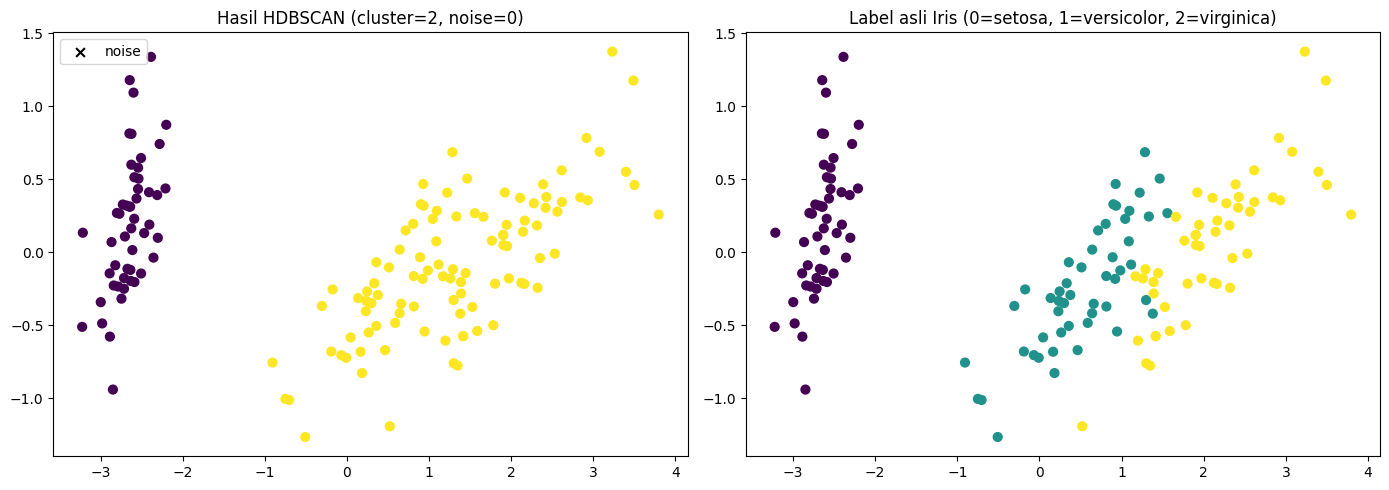

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Hasil cluster HDBSCAN (noise = hitam x)
mask_noise = labels == -1
axes[0].scatter(X_2d[~mask_noise, 0], X_2d[~mask_noise, 1], c=labels[~mask_noise],
                cmap='viridis', s=40)
axes[0].scatter(X_2d[mask_noise, 0], X_2d[mask_noise, 1], c='black', marker='x', s=40, label='noise')
axes[0].set_title(f'Hasil HDBSCAN (cluster={n_clusters}, noise={n_noise})')
axes[0].legend()

# Label asli
axes[1].scatter(X_2d[:, 0], X_2d[:, 1], c=y_true, cmap='viridis', s=40)
axes[1].set_title('Label asli Iris (0=setosa, 1=versicolor, 2=virginica)')

plt.tight_layout()
plt.show()

In [5]:
# Seberapa cocok hasil cluster dengan label asli? (tabel silang + Adjusted Rand Index)
import pandas as pd
from sklearn.metrics import adjusted_rand_score

crosstab = pd.crosstab(pd.Series(labels, name='cluster HDBSCAN'),
                       pd.Series(y_true, name='label asli'))
print(crosstab)
print()
print(f'Adjusted Rand Index (ARI): {adjusted_rand_score(y_true, labels):.4f}')

label asli        0   1   2
cluster HDBSCAN            
0                50   0   0
1                 0  50  50

Adjusted Rand Index (ARI): 0.5681


## 4. Analisis Singkat

**Apakah hasil clustering HDBSCAN sesuai dengan label asli dataset Iris?**

1. **Cluster 0 = Iris-setosa** (sempurna): seluruh sampel setosa membentuk satu cluster tersendiri tanpa campuran. Pada ruang PCA terlihat setosa terpisah jauh dari dua spesies lainnya - kepadatan dan jaraknya konsisten sehingga HDBSCAN dengan mudah mengenalinnya.
2. **Cluster 1 = gabungan versicolor + virginica**: kedua spesies ini memang tumpang tindih di ruang fitur (terlihat pada plot label asli), sehingga dari perspektif kepadatan (tanpa label) keduanya merupakan satu wilayah kepadatan yang sama - HDBSCAN menggabungkannya menjadi satu cluster. Seluruh titik tetap terklaster (tidak ada noise) pada parameter yang dipakai - kepadatan di perbatasan masih dinilai cukup untuk keanggotaan penuh.
3. **Noise = 0 data**: dengan parameter tersebut HDBSCAN menilai seluruh titik cukup padat untuk masuk ke sebuah cluster. Noise baru akan muncul bila `min_samples` diperbesar (model lebih konservatif) - titik di daerah kepadatan rendah akan ditandai noise (label -1).
4. **ARI = 0.5681** menunjukkan kesesuaian yang cukup baik dengan struktur label asli, dengan catatan bahwa pembagian versicolor-virginica memang tidak dapat dipisahkan secara tak-supervisi oleh metode kepadatan mana pun pada fitur asli.

**Kesimpulan:** hasil HDBSCAN **sebagian sesuai** dengan label asli: spesies yang terpisah jelas (setosa) ditemukan sempurna, sementara dua spesies yang tumpang tindih bergabung menjadi satu cluster kepadatan yang sama. Ini konsisten dengan karakter HDBSCAN sebagai metode berbasis kepadatan yang menemukan struktur alami data, bukan memaksakan jumlah kelas.